<a href="https://colab.research.google.com/github/youssefouabir-lab/Introduction_to_ai/blob/main/Lesson_9_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lesson 9 assignment**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
# 1. Load & preprocess data
raw = fetch_california_housing(as_frame=True)
df = raw.data.sample(2500, random_state=42).copy()  # sample keeps hierarchical & plots snappy
df["coastal_zone"] = np.where(df["Longitude"] > -120.5, "Inland", "Coastal")

# Inject a few NaNs just to demonstrate missing-value handling cleanly
rng = np.random.default_rng(42)
df.loc[rng.choice(df.index, 25, replace=False), "AveOccup"] = np.nan

num_cols = [c for c in df.columns if c != "coastal_zone"]
cat_cols = ["coastal_zone"]

prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
])
X = prep.fit_transform(df)

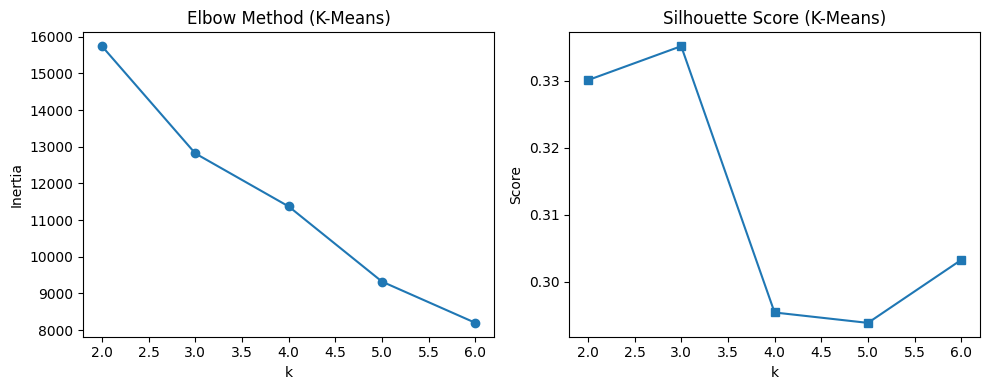

In [3]:
# 2. Optimal k via Elbow (inertia) & Silhouette score for K-Means
ks = range(2, 7)
inertias, sil_km = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_km.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("Elbow Method (K-Means)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sil_km, marker="s"); axes[1].set_title("Silhouette Score (K-Means)"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

best_k = ks[int(np.argmax(sil_km))]
km_labels = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(X)
hc_labels = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X)

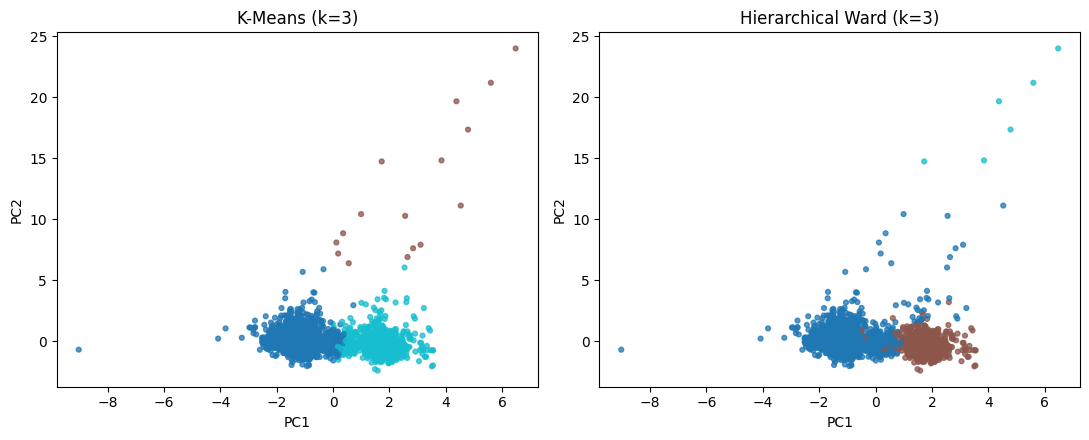

In [4]:
# 3. Dimensionality reduction (2D PCA) & cluster visualization
X_2d = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lbl, title in zip(axes, [km_labels, hc_labels], [f"K-Means (k={best_k})", f"Hierarchical Ward (k={best_k})"]):
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=lbl, cmap="tab10", s=12, alpha=0.75)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

In [5]:
# 4. Evaluation summary
for name, lbl in [("K-Means", km_labels), ("Hierarchical", hc_labels)]:
    print(f"{name:12s} | k={best_k} | Silhouette={silhouette_score(X, lbl):.3f} | Davies-Bouldin={davies_bouldin_score(X, lbl):.3f}")

K-Means      | k=3 | Silhouette=0.335 | Davies-Bouldin=1.040
Hierarchical | k=3 | Silhouette=0.317 | Davies-Bouldin=0.957
